In [32]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from scipy.io import wavfile
import scipy.io
from sklearn import svm

d = os.listdir()
if "Model_1" in d:
    os.chdir("Model_1") # Just some logic to be able to re-run cell in Jupyter notebook, as multiple runs changes the cwd.

print("Imports complete")
print("Running from: " + os.getcwd())
print("Please place dataset *one level up* from this folder.")
os.chdir("..")

Imports complete
Running from: C:\Users\leona\Documents\Krona\Hoost 2026\AI and Machine Learning\Project\Model_1
Please place dataset *one level up* from this folder.


In [2]:
train_path = r"\IDMT-ISA-ELECTRIC-ENGINE\train_cut/"
t_path_good = os.getcwd() + train_path + "engine1_good"
t_path_broken = os.getcwd() + train_path + "engine2_broken"
t_path_heavy = os.getcwd() + train_path + "engine3_heavyload"

good_samples_count = len(os.listdir(t_path_good))
broken_samples_count = len(os.listdir(t_path_broken))
heavy_samples_count = len(os.listdir(t_path_heavy))

rate, test = wavfile.read(os.path.join(t_path_good, os.listdir(t_path_good)[0]))
good_n = test.shape[0] # Each WAV file happens to be same amount of samples, so no need to test all of them.

train_good = np.zeros((good_samples_count, good_n))
train_broken = np.zeros((broken_samples_count, good_n))
train_heavy = np.zeros((heavy_samples_count, good_n))

print("Reading train_cut_good...")
for idx, e in enumerate(os.listdir(t_path_good)):
    _, data = wavfile.read(os.path.join(t_path_good, e))
    train_good[idx] = data
    
print("Reading train_cut_bad...")
for idx, e in enumerate(os.listdir(t_path_broken)):
    _, data = wavfile.read(os.path.join(t_path_broken, e))
    train_broken[idx] = data
    
print("Reading train_cut_heavy...")
for idx, e in enumerate(os.listdir(t_path_heavy)):
    _, data = wavfile.read(os.path.join(t_path_heavy, e))
    train_heavy[idx] = data

print("Done.")

Reading train_cut_good...
Reading train_cut_bad...
Reading train_cut_heavy...
Done.


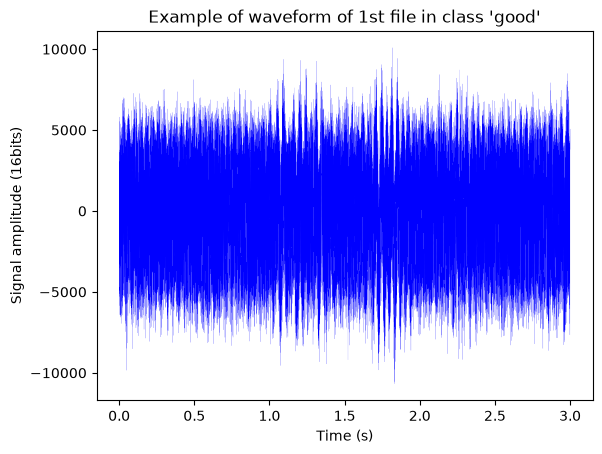

In [3]:
t = np.arange(0.0, 3.0, 1/rate)

plt.figure()
plt.plot(t, train_good[0], lw=0.075, color="blue")
plt.xlabel("Time (s)")
plt.ylabel("Signal amplitude (16bits)")
plt.title("Example of waveform of 1st file in class 'good'")
plt.show()

In [94]:
binN = 50

# No concatenation of two sample sets.
def get_features_single(inpA):
    inp = np.zeros((inpA.shape[0], binN))
    for i in range(inpA.shape[0]):
        inp[i] = np.histogram(tot[i], bins=binN)[0]
    print("Input shape: " + str(inp.shape))
    return inp

def get_features(inpA, inpB):
    tot = np.concatenate((inpA, inpB))
    inp = np.zeros((inpA.shape[0]+inpB.shape[0], binN))
    for i in range(inpA.shape[0]+inpB.shape[0]):
        inp[i] = np.histogram(tot[i], bins=binN)[0]
    print("Input shape: " + str(inp.shape))
    return inp

def create_target(inpA, inpB):
    a = np.ones(inpA.shape[0])
    b = np.zeros(inpB.shape[0])
    target = np.concatenate((a,b))
    print("Target shape: " + str(target.shape))
    return target

def create_svm(target, inp):
    x_train, x_test, y_train, y_test = train_test_split(inp, target, test_size=0.3, random_state=42)

    sc = StandardScaler() # Not really needed for histogram features, and results are same without scaling.
    x_train_sc = sc.fit_transform(x_train)
    x_test_sc = sc.transform(x_test)
    
    model = svm.SVC(kernel='linear', C=1, random_state=42)
    model.fit(x_train_sc, y_train)
    
    y_pred = model.predict(x_test_sc)
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
    
    return model

In [95]:
## GOOD vs BROKEN
target_gb = create_target(train_good, train_broken)
inp_gb = get_features(train_good, train_broken)
model_gb = create_svm(target_gb, inp_gb)
scores = cross_val_score(model_gb, inp_gb, target_gb, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")
print()

## BROKEN vs HEAVY
target_bh =  create_target(train_broken, train_heavy)
inp_bh = get_features(train_broken, train_heavy)
model_bh = create_svm(target_bh, inp_bh)
scores = cross_val_score(model_bh, inp_bh, target_bh, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")
print()

## GOOD vs HEAVY
target_gh = create_target(train_good, train_heavy)
inp_gh = get_features(train_good, train_heavy)
model_gh = create_svm(target_gh, inp_gh)
scores = cross_val_score(model_gh, inp_gh, target_gh, cv=5)
print(f"5-fold cross validation: {scores.mean():.3f} +/- {scores.std():.3f}")

Target shape: (229,)
Input shape: (229, 50)
Accuracy: 1.000
5-fold cross validation: 0.996 +/- 0.009

Target shape: (252,)
Input shape: (252, 50)
Accuracy: 0.987
5-fold cross validation: 0.996 +/- 0.008

Target shape: (233,)
Input shape: (233, 50)
Accuracy: 1.000
5-fold cross validation: 0.996 +/- 0.009


In [119]:
def three_fold_predict(svm_gb, svm_bh, svm_gh, inp):
    if len(inp.shape) == 1:
        data = np.ndarray(shape=(1, inp.shape[0]))
        data[0] = inp
    else:
        data = inp

    # Maps the 3 SVMs binary votes to the class they are actually voting on.
    voting_map = {
        "gb" : {
            0 : 0,
            1 : 1
        },
        "bh" : {
            0 : 1,
            1 : 2
        },
        "gh" : {
            0 : 0,
            1 : 2
        }
    }
    output = np.zeros(shape=(3))

    sc = StandardScaler()
    data = sc.fit_transform(data)
    
    a = svm_gb.predict(data)
    b = svm_bh.predict(data)
    c = svm_gh.predict(data)
    
    for i in range(len(a)):
        output[voting_map["gb"][a[i]]] += 1
        output[voting_map["bh"][b[i]]] += 1
        output[voting_map["gh"][c[i]]] += 1
    
    print(output)

    return 0

In [120]:
test = get_features_single(train_good)
three_fold_predict(model_gb, model_bh, model_gh, test)

Input shape: (105, 50)
[ 85. 124. 106.]


0